In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("../data/processed/train_features_138.csv")
test = pd.read_csv("../data/processed/test_features_138.csv")

X = train.drop(columns=["id", "target"])
y = train["target"]

X_test = test.drop(columns=["id"])

print("X:", X.shape)
print("y:", y.shape)
print("X_test:", X_test.shape)
print("Classes:", y.nunique())

X: (635, 138)
y: (635,)
X_test: (403, 138)
Classes: 12


In [2]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (508, 138)
X_val: (127, 138)
y_train: (508,)
y_val: (127,)


In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (508, 138)
Validation: (127, 138)
Test: (403, 138)


In [4]:
from sklearn.decomposition import PCA

pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)

X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Train PCA:", X_train_pca.shape)
print("Validation PCA:", X_val_pca.shape)
print("Test PCA:", X_test_pca.shape)

Train PCA: (508, 138)
Validation PCA: (127, 138)
Test PCA: (403, 138)


In [5]:
explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

print("First 10 components:")
print(explained_variance[:10])

print("\nCumulative variance:")
print(cumulative_variance[:10])

print("\nComponents for 90% variance:",
      np.argmax(cumulative_variance >= 0.90) + 1)

print("Components for 95% variance:",
      np.argmax(cumulative_variance >= 0.95) + 1)

First 10 components:
[0.13513917 0.05407736 0.03685774 0.03048516 0.02709179 0.02538059
 0.02407863 0.02315156 0.02240411 0.02091409]

Cumulative variance:
[0.13513917 0.18921653 0.22607427 0.25655943 0.28365122 0.30903181
 0.33311044 0.356262   0.37866612 0.3995802 ]

Components for 90% variance: 60
Components for 95% variance: 72


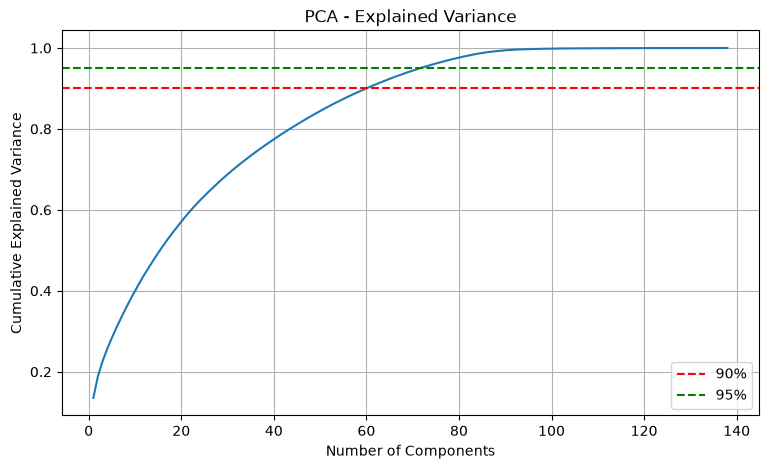

In [6]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.axhline(y=0.90, color='red', linestyle='--', label='90%')
plt.axhline(y=0.95, color='green', linestyle='--', label='95%')

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.legend()
plt.grid()
plt.show()

In [7]:
pca_60 = PCA(n_components=60)

X_train_pca60 = pca_60.fit_transform(X_train_scaled)
X_val_pca60 = pca_60.transform(X_val_scaled)
X_test_pca60 = pca_60.transform(X_test_scaled)

print("Train:", X_train_pca60.shape)
print("Validation:", X_val_pca60.shape)
print("Test:", X_test_pca60.shape)

print("Variance preserved:",
      pca_60.explained_variance_ratio_.sum())

Train: (508, 60)
Validation: (127, 60)
Test: (403, 60)
Variance preserved: 0.899516544051719


In [9]:
# Convert PCA arrays into DataFrames
pca_train_df = pd.DataFrame(
    X_train_pca60,
    columns=[f"PC{i+1}" for i in range(60)],
    index=X_train.index
)

pca_val_df = pd.DataFrame(
    X_val_pca60,
    columns=[f"PC{i+1}" for i in range(60)],
    index=X_val.index
)

pca_test_df = pd.DataFrame(
    X_test_pca60,
    columns=[f"PC{i+1}" for i in range(60)]
)

# Preserve IDs and target
pca_train_df.insert(0, "id", train.loc[X_train.index, "id"])
pca_train_df["target"] = y_train

pca_val_df.insert(0, "id", train.loc[X_val.index, "id"])
pca_val_df["target"] = y_val

pca_test_df.insert(0, "id", test["id"].values)

# Save separately
pca_train_df.to_csv("../experiments/pca/train_pca60.csv", index=False)
pca_val_df.to_csv("../experiments/pca/val_pca60.csv", index=False)
pca_test_df.to_csv("../experiments/pca/test_pca60.csv", index=False)

print(pca_train_df.shape)
print(pca_val_df.shape)
print(pca_test_df.shape)

(508, 62)
(127, 62)
(403, 61)


In [10]:
pca_train_df.to_csv("../experiments/pca/train_pca60.csv", index=False)
pca_val_df.to_csv("../experiments/pca/val_pca60.csv", index=False)
pca_test_df.to_csv("../experiments/pca/test_pca60.csv", index=False)

print("PCA datasets saved successfully!")

PCA datasets saved successfully!


In [11]:
pca_72 = PCA(n_components=72)

X_train_pca72 = pca_72.fit_transform(X_train_scaled)
X_val_pca72 = pca_72.transform(X_val_scaled)
X_test_pca72 = pca_72.transform(X_test_scaled)

print("Train:", X_train_pca72.shape)
print("Validation:", X_val_pca72.shape)
print("Test:", X_test_pca72.shape)

print("Variance preserved:",
      pca_72.explained_variance_ratio_.sum())

Train: (508, 72)
Validation: (127, 72)
Test: (403, 72)
Variance preserved: 0.9514372026423141


In [12]:
from sklearn.decomposition import PCA

pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)

X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Train PCA:", X_train_pca.shape)
print("Validation PCA:", X_val_pca.shape)
print("Test PCA:", X_test_pca.shape)

Train PCA: (508, 138)
Validation PCA: (127, 138)
Test PCA: (403, 138)


In [13]:
pca_train72 = pd.DataFrame(
    X_train_pca72,
    columns=[f"PC{i+1}" for i in range(72)],
    index=X_train.index
)

pca_val72 = pd.DataFrame(
    X_val_pca72,
    columns=[f"PC{i+1}" for i in range(72)],
    index=X_val.index
)

pca_test72 = pd.DataFrame(
    X_test_pca72,
    columns=[f"PC{i+1}" for i in range(72)]
)

pca_train72.insert(0, "id", train.loc[X_train.index, "id"])
pca_train72["target"] = y_train

pca_val72.insert(0, "id", train.loc[X_val.index, "id"])
pca_val72["target"] = y_val

pca_test72.insert(0, "id", test["id"].values)

pca_train72.to_csv("../experiments/pca/train_pca72.csv", index=False)
pca_val72.to_csv("../experiments/pca/val_pca72.csv", index=False)
pca_test72.to_csv("../experiments/pca/test_pca72.csv", index=False)

print("95% PCA datasets saved!")

95% PCA datasets saved!
